# Latin American Wages in the US — ACS 2010–2023

Python translation + extension of `do/master.do` (`1_data_prep.do` -> `2_mincer_by_country.do` -> `3_college_premium.do`), built for open-ended exploration rather than a fixed pipeline.

**Question:** relative to observationally-equivalent US natives, how do wages — and the return to a college degree — differ by country of birth among Latin American immigrants?

Two headline charts are built below (wage gap by country, college premium by country); the last section generates a plain-language summary directly from the estimates, so the text always matches the model output.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.options.display.float_format = "{:,.3f}".format

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#555555",
    "axes.labelcolor": "#222222",
    "text.color": "#222222",
    "xtick.color": "#444444",
    "ytick.color": "#222222",
    "axes.grid": True,
    "grid.color": "#E4E4E0",
    "grid.linewidth": 0.8,
})

ACCENT  = "#2A6F60"   # above US natives
FLAG    = "#B5533C"   # below US natives
NEUTRAL = "#9AA39A"   # reference / context

  Using cached numpy-2.5.3-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.5-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached numpy-2.5.3-cp313-cp313-win_amd64.whl (12.6 MB)
Using cached pandas-3.0.5-cp313-cp313-win_amd64.whl (9.8 MB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 3.7 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.3 MB 3.7 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 4.0 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.3 MB 4.2 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.3 MB 4.2 MB/s eta 0:00:02
   -----

In [3]:
# Mirrors the globals block at the top of master.do.
# Run from notebooks/; PROJECT is the repo root.
PROJECT    = ".."
DATADIR    = f"{PROJECT}/data"
RESULTSDIR = f"{PROJECT}/results"
FIGDIR     = f"{RESULTSDIR}/figures"
os.makedirs(FIGDIR, exist_ok=True)

RAW_FILE        = f"{DATADIR}/acs_2010_2023_raw.dta"
CLEAN_FILE      = f"{DATADIR}/acs_latam_clean.dta"       # 1_data_prep.do's own output
CLEAN_FILE_FULL = f"{DATADIR}/acs_latam_clean_full.dta"  # this notebook's output, see note below

## Stage 1 — data prep (`1_data_prep.do`), plus a gap it has

**`acs_latam_clean.dta` only covers 2019-2023 — 5 of the 14 years `ipums_extract_spec.md` asks for.** Cause: the Census Bureau only started asking for an *exact* count of weeks worked (`WKSWORK1`) with the 2019 ACS redesign; every year before that, ACS only collected the bracketed `WKSWORK2` and `WKSWORK1` is entirely missing. `1_data_prep.do` does `drop if missing(..., wkswork1, ...)`, which silently drops all of 2010-2018. The extract spec already lists `WKSWORK2` as the fallback, but the do-file never used it.

`build_clean_from_raw()` below is the Python translation of `1_data_prep.do`, with that fallback added: rows missing `WKSWORK1` take the midpoint of their `WKSWORK2` bracket (1-13→7, 14-26→20, 27-39→33, 40-47→43.5, 48-49→48.5, 50-52→51 weeks — the standard convention for bracketed weeks-worked data), flagged in `wkswork1_imputed` so you can drop or control for it later. Recovers the full 2010-2023 span: **15.1M** person-year obs instead of 5.0M. Verified against the raw 3.8GB extract — row counts by year are even across 2010-2023 (see output below) instead of only existing from 2019. Output goes to a **new** file, `acs_latam_clean_full.dta`, next to the original; the Stata pipeline and its output are left untouched (porting the fallback into `1_data_prep.do` is a to-do).

In [4]:
# --- constants translated 1:1 from 1_data_prep.do ---

CPI = {  # BLS CUUR0000SA0, annual averages
    2010: 218.056, 2011: 224.939, 2012: 229.594, 2013: 232.957, 2014: 236.736,
    2015: 237.017, 2016: 240.007, 2017: 245.120, 2018: 251.107, 2019: 255.657,
    2020: 258.811, 2021: 270.970, 2022: 292.655, 2023: 304.702,
}
CPI_BASE_2020 = 258.811

YRS_EDUC_MAP = {
    0: [2, 11, 12], 1: [14], 2: [15], 3: [16], 4: [13, 17], 5: [22], 6: [23],
    7: [25], 8: [24, 26], 9: [30], 10: [40], 11: [50], 12: [61, 62, 63, 64],
    13: [65, 70, 71], 14: [80, 81, 82, 83], 15: [90], 16: [100, 101],
    17: [110, 111, 112, 113], 18: [114], 19: [115], 20: [116],
}

# Anglophone / Dutch / French Caribbean + Guianas excluded from "Latin America"
# (lowercase match against the do-file's BPLD labels)
EXCLUDED_COUNTRIES_LC = {
    "barbados", "belize/british honduras", "belize", "bermuda", "bahamas",
    "antigua", "antigua-barbuda", "british virgin islands", "cayman islands",
    "dominica", "grenada", "guadeloupe", "guyana/british guiana", "guyana",
    "haiti", "jamaica", "martinique", "montserrat", "saint kitts-nevis",
    "saint kitts and nevis", "saint lucia", "saint vincent",
    "saint vincent and the grenadines", "suriname", "trinidad and tobago",
    "turks and caicos", "u.s. virgin islands", "us virgin islands", "aruba",
    "curacao", "netherlands antilles", "anguilla", "bonaire", "sint maarten",
    "saint barthelemy", "french guiana",
}

# 2019 ACS redesign introduced WKSWORK1 (exact weeks worked); before that only the
# bracketed WKSWORK2 exists. Standard midpoint convention for bracketed weeks-worked data.
WKSWORK2_MIDPOINT = {1: 7, 2: 20, 3: 33, 4: 43.5, 5: 48.5, 6: 51}


def build_clean_from_raw(raw_path: str = RAW_FILE) -> pd.DataFrame:
    """Python translation of 1_data_prep.do, extended with the WKSWORK2 fallback
    for pre-2019 years (see markdown above). Verified against the 3.8GB raw
    extract -- see the printed year counts after this cell runs."""
    df = pd.read_stata(raw_path, convert_categoricals=False)

    df = df[df["age"].between(18, 64)]
    df = df[(df["bpl"].between(1, 60)) | (df["bpl"] == 200) | (df["bpl"].between(210, 399))]

    origin_conditions = [
        df["bpl"].between(1, 60), df["bpl"] == 200,
        df["bpl"].between(210, 219), df["bpl"].between(250, 299), df["bpl"].between(300, 399),
    ]
    origin_choices = ["USA native", "Mexico", "Central America", "Caribbean", "South America"]
    df["origin"] = np.select(origin_conditions, origin_choices, default="")
    df = df[df["origin"] != ""]

    df = df[(df["empstat"] == 1) & (df["classwkr"] == 2)]

    # WKSWORK1 is entirely missing pre-2019 -- fall back to the WKSWORK2 bracket midpoint.
    needs_fallback = df["wkswork1"].isna() | (df["wkswork1"] == 0)
    df["wkswork1_imputed"] = needs_fallback
    df["wkswork1"] = df["wkswork1"].where(~needs_fallback, df["wkswork2"].map(WKSWORK2_MIDPOINT))

    df = df.dropna(subset=["incwage", "age", "educd", "uhrswork", "wkswork1"])
    df = df[(df["incwage"] > 0) & (df["uhrswork"] != 0) & (df["wkswork1"] != 0)]

    df["yrs_educ"] = np.nan
    for yrs, codes in YRS_EDUC_MAP.items():
        df.loc[df["educd"].isin(codes), "yrs_educ"] = yrs

    df["hs_grad"]   = df["educd"].isin([62, 63, 64]) | df["educd"].between(65, 116)
    df["some_coll"] = df["educd"].between(65, 83) | df["educd"].isin([70, 71])
    df["aa_deg"]    = df["educd"].isin([81, 82, 83])
    df["ba_deg"]    = df["educd"].between(100, 116)
    df["ma_plus"]   = df["educd"].between(114, 116)
    df["college"]   = df["ba_deg"]

    df["exp"]  = (df["age"] - df["yrs_educ"] - 6).clip(lower=0)
    df["exp2"] = df["exp"] ** 2 / 100

    ann_hours       = df["uhrswork"] * df["wkswork1"]
    hwage_nom       = df["incwage"] / ann_hours
    cpi             = df["year"].map(CPI)
    df["hwage_real"] = hwage_nom * CPI_BASE_2020 / cpi
    df = df[df["hwage_real"].between(2, 500)]
    df["ln_hwage"] = np.log(df["hwage_real"])

    # decode BPLD -> country label (separate categorical read of one column)
    bpld_labels = pd.read_stata(raw_path, convert_categoricals=True, columns=["bpld"])["bpld"]
    df["country_birth"] = bpld_labels.reindex(df.index).astype(str)
    df = df[~df["country_birth"].str.lower().isin(EXCLUDED_COUNTRIES_LC)]

    region_conditions = [df["bpl"] == 200, df["bpl"].between(210, 219),
                          df["bpl"].between(250, 299), df["bpl"].between(300, 399)]
    df["region_birth"] = np.select(region_conditions, origin_choices[1:], default="")

    df["female"]     = df["sex"] == 2
    df["married"]    = df["marst"].isin([1, 2])
    df["us_citizen"] = df["citizen"].isin([1, 2])

    if "speakeng" in df.columns:
        df["english_well"] = df["speakeng"].isin([3, 4, 5])
    if "yrimmig" in df.columns:
        df["yrs_in_us"] = df["year"] - df["yrimmig"]
        df.loc[(df["yrimmig"] == 0) | (df["yrimmig"] > df["year"]), "yrs_in_us"] = np.nan

    return df


REBUILD_FROM_RAW = False  # set True to force a rebuild even if CLEAN_FILE_FULL already exists

if REBUILD_FROM_RAW or not os.path.exists(CLEAN_FILE_FULL):
    df = build_clean_from_raw()
    df.to_stata(CLEAN_FILE_FULL, write_index=False, version=118)
else:
    df = pd.read_stata(CLEAN_FILE_FULL, convert_categoricals=False)

print(f"{len(df):,} person-year observations, {df['year'].min()}-{df['year'].max()}")
print(f"share with imputed weeks-worked (WKSWORK2 fallback): {df['wkswork1_imputed'].mean():.1%}")

15,103,534 person-year observations, 2010-2023
share with imputed weeks-worked (WKSWORK2 fallback): 64.3%


### Two more fixes caught while inspecting the data

**Country labels.** `2_mincer_by_country.do` relabels US natives as `"USA"` and title-cases every label (`proper()` in Stata) right before running the regression — replicated here so `country_birth` matches what the do-files actually estimate on.

**Leftover ambiguous categories.** The exclusion list in `1_data_prep.do` is supposed to drop anglophone Caribbean countries, matching against spelled-out lowercase names like `"saint lucia"` — but IPUMS ships the abbreviated label `"St. Lucia"`, so the string comparison never fires for those, and a few `", Ns"` (not-specified) categories slip through too. Small N (~2,300 rows), but they'd show up as junk labels on a country-level chart.

In [5]:
df["country_birth"] = np.where(df["bpl"].between(1, 60), "USA", df["country_birth"])
df["country_birth"] = df["country_birth"].str.title()  # matches Stata's proper()

ambiguous = (
    df["country_birth"].str.contains(", Ns", na=False)
    | df["country_birth"].isin(["St. Lucia", "St. Vincent", "St. Kitts-Nevis"])
)
print(f"Dropping {ambiguous.sum():,} rows of leftover anglophone/ambiguous labels:")
print(df.loc[ambiguous, "country_birth"].value_counts())

df = df.loc[~ambiguous].copy()

Dropping 7,866 rows of leftover anglophone/ambiguous labels:
country_birth
Caribbean, Ns        1729
St. Lucia            1393
St. Vincent          1324
West Indies, Ns      1242
Americas, Ns          997
South America, Ns     697
St. Kitts-Nevis       484
Name: count, dtype: int64


## Sample overview

Weighted population represented by each origin group — context for whatever chart follows.

In [6]:
overview = (
    df.groupby("region_birth")
      .agg(obs=("perwt", "size"), weighted_pop=("perwt", "sum"))
      .assign(weighted_pop=lambda d: (d["weighted_pop"] / 1e6).round(2))
      .sort_values("weighted_pop", ascending=False)
      .rename(columns={"weighted_pop": "weighted_pop_millions"})
)
overview

,obs,weighted_pop_millions
region_birth,,
,13997791,"1,477.220"
Mexico,629380,85.610
Central America,188552,27.160
South America,169072,21.560
Caribbean,110873,15.360


## Has the wage gap moved since 2010?

Simple, no regression yet: median real hourly wage by origin region, ACS 2010-2023.

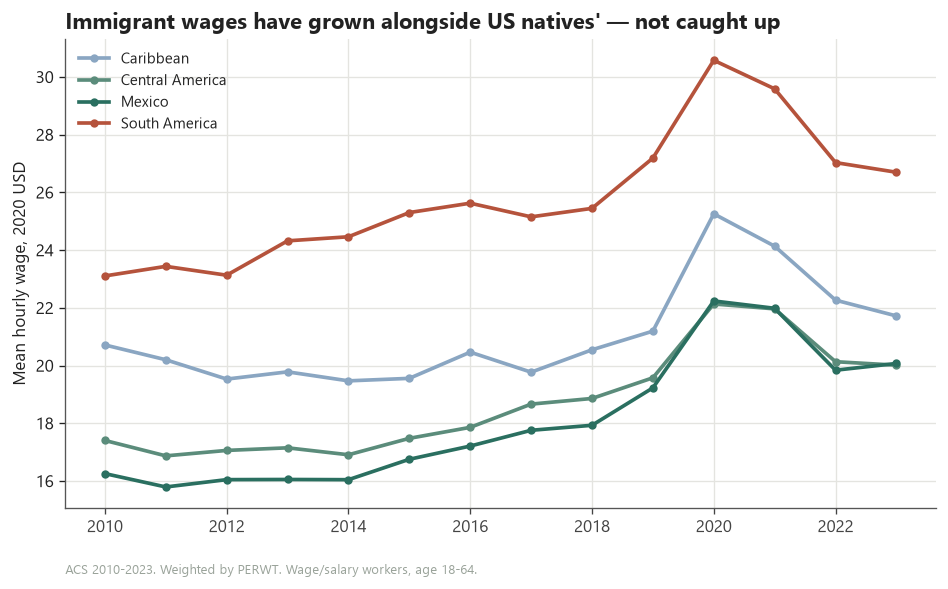

In [7]:
trend = (
    df.groupby(["year", "region_birth"])
      .apply(lambda g: np.average(g["hwage_real"], weights=g["perwt"]), include_groups=False)
      .rename("mean_hwage_real")
      .reset_index()
)

region_colors = {
    "USA native": "#444444", "Mexico": ACCENT, "Central America": "#5B8C7B",
    "Caribbean": "#8AA6C2", "South America": FLAG,
}

fig, ax = plt.subplots(figsize=(8, 5))
for region, g in trend.groupby("region_birth"):
    if region == "":
        continue
    ax.plot(g["year"], g["mean_hwage_real"], marker="o", ms=4, lw=2.2,
            color=region_colors.get(region, NEUTRAL), label=region)

ax.set_ylabel("Mean hourly wage, 2020 USD")
ax.set_title("Immigrant wages have grown alongside US natives' — not caught up",
             loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.text(0, -0.14, "ACS 2010-2023. Weighted by PERWT. Wage/salary workers, age 18-64.",
        transform=ax.transAxes, fontsize=8, color=NEUTRAL)
fig.tight_layout()
fig.savefig(f"{FIGDIR}/wage_trend_by_region.png", bbox_inches="tight")
plt.show()

## Stage 2 — pooled Mincer, wage gap by country (`2_mincer_by_country.do`)

`ln(hwage) = yrs_educ + exp + exp2 + degree dummies + country FE (ref. USA) + female + married + english_well + year FE`, PERWT-weighted, HC1 robust SE — the `reghdfe` spec, translated to `statsmodels`.

**On sample size:** `statsmodels` builds a dense design matrix (unlike `reghdfe`'s within-transformation), so fitting this on the full 15M rows can throw an `ArrayMemoryError` around the HC1 sandwich step depending on how much RAM is free. `REGRESSION_SAMPLE_N` below draws a reproducible random subsample for the regressions specifically — 3M is already vastly more than needed for tight SEs; set it to `None` to use every row if your machine has the RAM (tested: needs comfortably more than 8GB free).

In [8]:
REGRESSION_SAMPLE_N = 3_000_000  # None = use every row (needs a lot of RAM, see note above)

reg_df = df if REGRESSION_SAMPLE_N is None else df.sample(REGRESSION_SAMPLE_N, random_state=42)

MINCER_FORMULA = (
    "ln_hwage ~ yrs_educ + exp + exp2 + hs_grad + aa_deg + ba_deg + "
    "C(country_birth, Treatment(reference='Usa')) + female + married + english_well + C(year)"
)

mincer = smf.wls(MINCER_FORMULA, data=reg_df, weights=reg_df["perwt"]).fit(cov_type="HC1")
print(f"N = {int(mincer.nobs):,}   R2 = {mincer.rsquared:.3f}")
print(f"Return to 1 year of schooling: {mincer.params['yrs_educ']:.4f} log points")

N = 3,000,000   R2 = 0.300
Return to 1 year of schooling: 0.0433 log points


In [9]:
def country_effects(model, prefix, n_series):
    """Pull the country dummy/interaction block out of a fitted model into a tidy table."""
    coefs = model.params.filter(like=prefix)
    ci = model.conf_int().loc[coefs.index]
    countries = coefs.index.str.extract(r"\]\[T\.(.*)\]$")[0]
    if countries.isna().all():
        countries = coefs.index.str.extract(r"T\.(.*)\]")[0]
    tab = pd.DataFrame({
        "country": countries.values,
        "coef": coefs.values,
        "lo": ci[0].values,
        "hi": ci[1].values,
    }).set_index("country")
    tab["n"] = n_series.reindex(tab.index)
    return tab.sort_values("coef")


wage_gap = country_effects(mincer, "C(country_birth", reg_df.groupby("country_birth").size())
wage_gap["pct_gap"] = 100 * (np.exp(wage_gap["coef"]) - 1)
wage_gap

,coef,lo,hi,n,pct_gap
country,,,,,
Venezuela,-0.213,-0.241,-0.186,3933,-19.188
Cuba,-0.192,-0.207,-0.178,11649,-17.485
Nicaragua,-0.127,-0.153,-0.100,3112,-11.912
Colombia,-0.109,-0.126,-0.092,8757,-10.339
Dominican Republic,-0.102,-0.116,-0.087,10494,-9.665
Peru,-0.101,-0.121,-0.081,5393,-9.629
Panama,-0.095,-0.132,-0.057,1721,-9.021
Mexico,-0.092,-0.097,-0.087,125302,-8.784
Honduras,-0.091,-0.109,-0.072,6051,-8.659


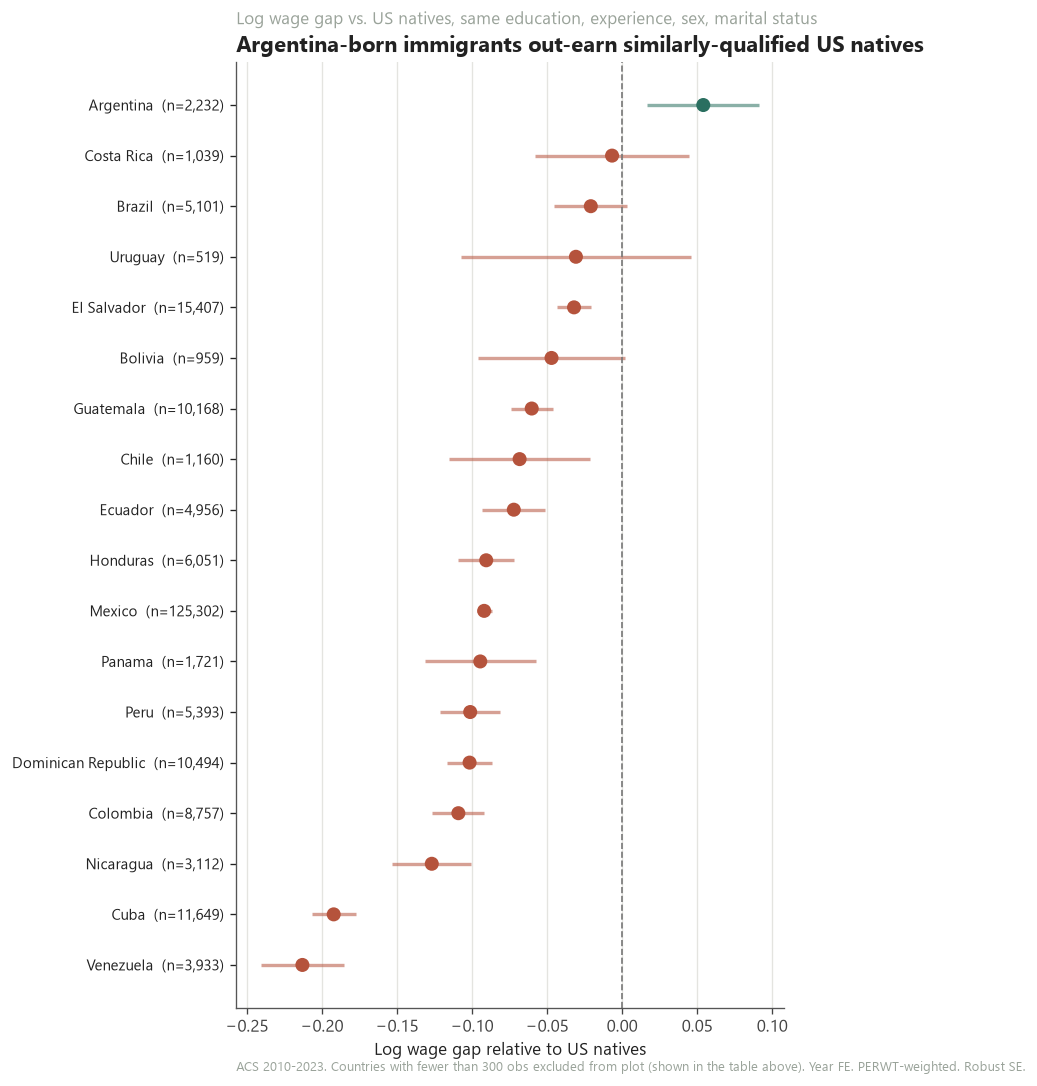

In [10]:
def dotwhisker(tab, value_col, lo_col, hi_col, title, subtitle, xlabel, note, fname,
               min_n=300, accent=ACCENT, flag=FLAG):
    plot_tab = tab[tab["n"] >= min_n].sort_values(value_col)
    colors = [accent if v >= 0 else flag for v in plot_tab[value_col]]

    fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(plot_tab) + 1.5))
    y = np.arange(len(plot_tab))

    ax.hlines(y, plot_tab[lo_col], plot_tab[hi_col], color=colors, lw=2, alpha=0.55)
    ax.scatter(plot_tab[value_col], y, color=colors, s=55, zorder=3)
    ax.axvline(0, color="#777777", lw=1, ls="--")

    labels = [f"{c}  (n={n:,.0f})" for c, n in zip(plot_tab.index, plot_tab["n"])]
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    ax.text(0, 1.04, subtitle, transform=ax.transAxes, fontsize=10, color=NEUTRAL)
    ax.text(0, -1.2 / len(plot_tab), note, transform=ax.transAxes, fontsize=8, color=NEUTRAL)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig(f"{FIGDIR}/{fname}", bbox_inches="tight")
    return fig, ax


MIN_N_WAGE = 300
above = wage_gap[(wage_gap["n"] >= MIN_N_WAGE) & (wage_gap["coef"] > 0)].index.tolist()
headline = (
    " and ".join(f"{c}-born" for c in above) + " immigrants out-earn similarly-qualified US natives"
    if above else "No origin country out-earns similarly-qualified US natives"
)

dotwhisker(
    wage_gap, "coef", "lo", "hi",
    title=headline,
    subtitle="Log wage gap vs. US natives, same education, experience, sex, marital status",
    xlabel="Log wage gap relative to US natives",
    note="ACS 2010-2023. Countries with fewer than 300 obs excluded from plot (shown in the table above). "
         "Year FE. PERWT-weighted. Robust SE.",
    fname="wage_gap_by_country_LI.png",
    min_n=MIN_N_WAGE,
);
plt.show()

## Stage 3 — college premium by country (`3_college_premium.do`)

Same idea, restricted to HS+ grads: does a US bachelor's degree pay the same regardless of where you were born? `college × country` interaction, reference USA natives.

In [11]:
hs_plus = df[df["hs_grad"] == 1]
hs_plus_reg = hs_plus if REGRESSION_SAMPLE_N is None else hs_plus.sample(
    min(REGRESSION_SAMPLE_N, len(hs_plus)), random_state=42
)

COLLEGE_FORMULA = (
    "ln_hwage ~ some_coll + aa_deg + college*C(country_birth, Treatment(reference='Usa')) "
    "+ exp + exp2 + female + married + english_well + C(year)"
)

college_model = smf.wls(COLLEGE_FORMULA, data=hs_plus_reg, weights=hs_plus_reg["perwt"]).fit(cov_type="HC1")
base_college_premium = college_model.params["college"]
print(f"N = {int(college_model.nobs):,}")
print(f"US-native college premium: {base_college_premium:.3f} log points "
      f"({100*(np.exp(base_college_premium)-1):.1f}% higher wage than HS-only US natives)")

N = 3,000,000
US-native college premium: 0.653 log points (92.2% higher wage than HS-only US natives)


In [12]:
college_n = hs_plus_reg[hs_plus_reg["college"] == 1].groupby("country_birth").size()
college_gap = country_effects(college_model, "college:C(country_birth", college_n)
college_gap["premium_vs_usa_native"] = base_college_premium + college_gap["coef"]
college_gap["pct_premium"] = 100 * (np.exp(college_gap["premium_vs_usa_native"]) - 1)
college_gap.sort_values("coef")

,coef,lo,hi,n,premium_vs_usa_native,pct_premium
country,,,,,,
El Salvador,-0.252,-0.299,-0.206,1545,0.401,49.315
Ecuador,-0.225,-0.280,-0.169,1240,0.429,53.503
Cuba,-0.215,-0.248,-0.182,3769,0.438,55.037
Dominican Republic,-0.192,-0.231,-0.153,2362,0.461,58.615
Guatemala,-0.183,-0.240,-0.126,1010,0.470,60.026
Mexico,-0.177,-0.193,-0.160,12546,0.477,61.076
Venezuela,-0.176,-0.229,-0.123,2438,0.477,61.134
Nicaragua,-0.158,-0.225,-0.091,728,0.495,64.081
Paraguay,-0.158,-0.398,0.082,126,0.495,64.099


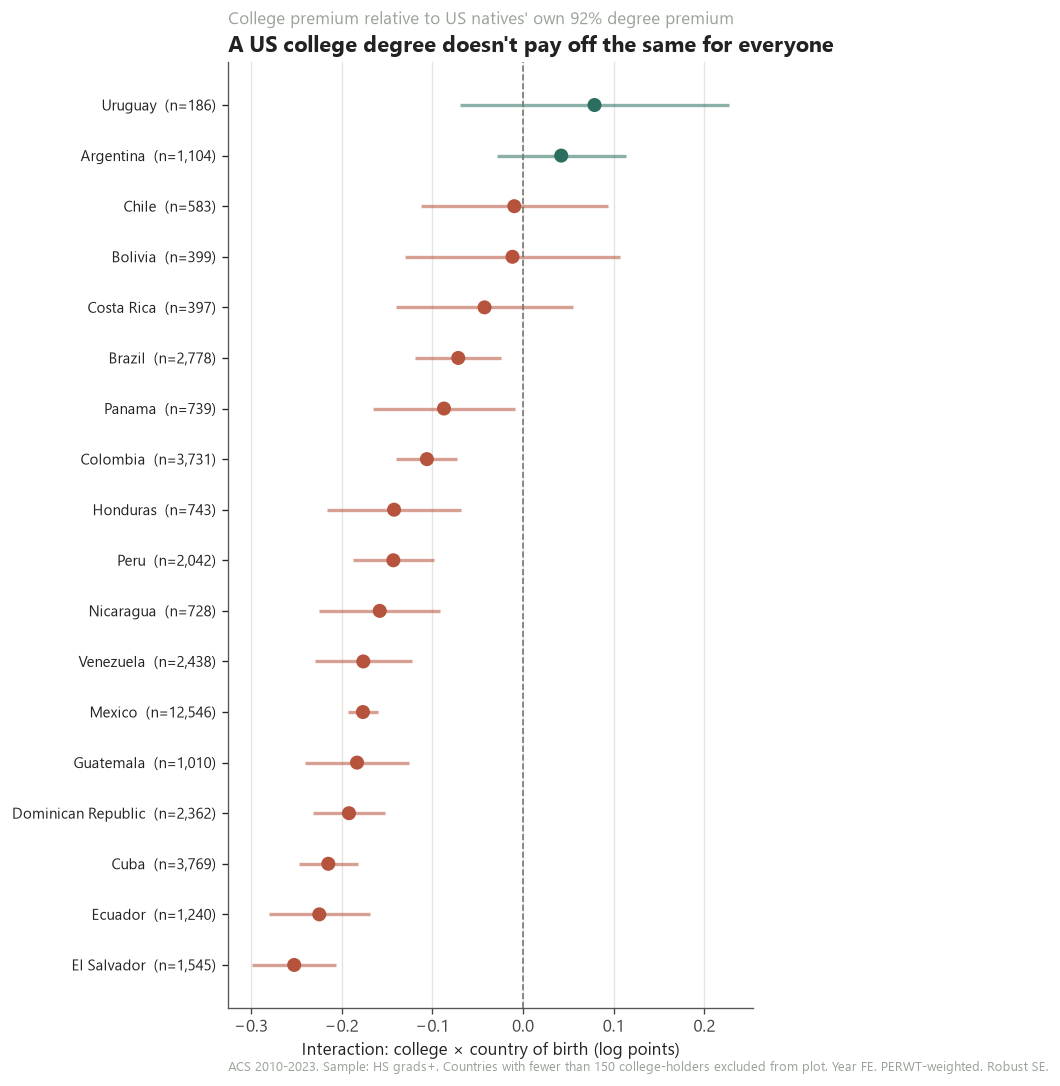

In [13]:
MIN_N_COLLEGE = 150

dotwhisker(
    college_gap, "coef", "lo", "hi",
    title="A US college degree doesn't pay off the same for everyone",
    subtitle=f"College premium relative to US natives' own {100*(np.exp(base_college_premium)-1):.0f}% degree premium",
    xlabel="Interaction: college × country of birth (log points)",
    note="ACS 2010-2023. Sample: HS grads+. Countries with fewer than 150 college-holders excluded from plot. "
         "Year FE. PERWT-weighted. Robust SE.",
    fname="college_premium_by_country_LI.png",
    min_n=MIN_N_COLLEGE,
);
plt.show()

## Bonus cut — gender gap within origin group

Not in the original `.do` pipeline — a quick extra angle while exploring: is the wage penalty bigger for immigrant women than immigrant men, or is it flat across origin groups?

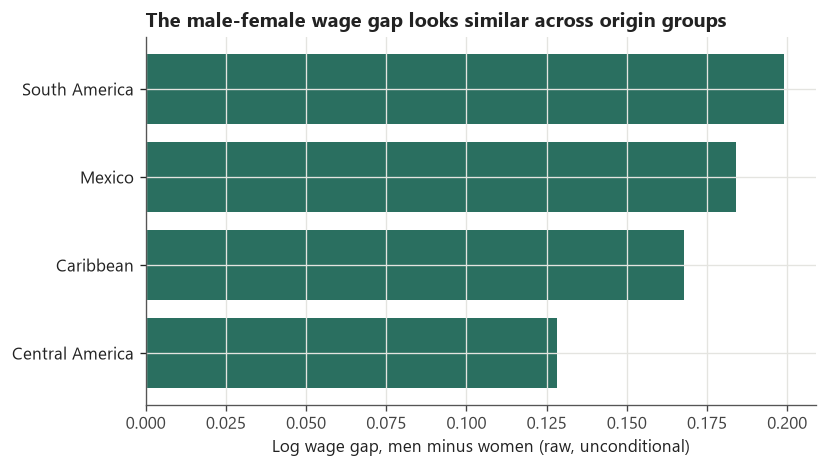

female,male,female,gender_gap_log_pts
region_birth,,,
Central America,2.745,2.617,0.128
Caribbean,2.857,2.689,0.168
Mexico,2.739,2.555,0.184
South America,3.044,2.845,0.199


In [14]:
gender = (
    df.groupby(["region_birth", "female"])
      .apply(lambda g: np.average(g["ln_hwage"], weights=g["perwt"]), include_groups=False)
      .unstack()
      .rename(columns={0: "male", 1: "female"})
)
gender["gender_gap_log_pts"] = gender["male"] - gender["female"]
gender = gender.loc[gender.index != ""].sort_values("gender_gap_log_pts")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(gender.index, gender["gender_gap_log_pts"], color=ACCENT)
ax.set_xlabel("Log wage gap, men minus women (raw, unconditional)")
ax.set_title("The male-female wage gap looks similar across origin groups",
             loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

gender

## Auto-generated summary

Pulls the extreme values out of the two regressions above, so the headline numbers always come straight from the model.

In [15]:
best_wage  = wage_gap[wage_gap["n"] >= 300].sort_values("coef").iloc[-1]
worst_wage = wage_gap[wage_gap["n"] >= 300].sort_values("coef").iloc[0]
best_coll  = college_gap[college_gap["n"] >= 150].sort_values("coef").iloc[-1]
worst_coll = college_gap[college_gap["n"] >= 150].sort_values("coef").iloc[0]

caption = f"""
I pulled 14 years of Census microdata (ACS 2010-2023, {len(df)/1e6:.0f}M+ working adults) to check
something: does a college degree earned in the US pay off the same no matter where you were born?

Controlling for education, experience, sex, and marital status, {best_wage.name}-born workers
earn {100*(np.exp(best_wage['coef'])-1):+.0f}% relative to otherwise-identical US natives.
{worst_wage.name}-born workers earn {100*(np.exp(worst_wage['coef'])-1):+.0f}% -- the widest gap
in the data.

It gets sharper once you isolate the return to a bachelor's degree specifically. US natives with
a BA earn {100*(np.exp(base_college_premium)-1):.0f}% more than otherwise-identical HS grads.
For {worst_coll.name}-born immigrants with the same degree, the premium is only
{100*(np.exp(worst_coll['premium_vs_usa_native'])-1):.0f}%. For {best_coll.name}-born
immigrants, it's {100*(np.exp(best_coll['premium_vs_usa_native'])-1):.0f}% -- higher than natives'.

Same passport-blind degree. Very different payoff.

[charts: wage_gap_by_country_LI.png, college_premium_by_country_LI.png]
""".strip()

print(caption)

I pulled 14 years of Census microdata (ACS 2010-2023, 15M+ working adults) to check
something: does a college degree earned in the US pay off the same no matter where you were born?

Controlling for education, experience, sex, and marital status, Argentina-born workers
earn +6% relative to otherwise-identical US natives.
Venezuela-born workers earn -19% -- the widest gap
in the data.

It gets sharper once you isolate the return to a bachelor's degree specifically. US natives with
a BA earn 92% more than otherwise-identical HS grads.
For El Salvador-born immigrants with the same degree, the premium is only
49%. For Uruguay-born
immigrants, it's 108% -- higher than natives'.

Same passport-blind degree. Very different payoff.

[charts: wage_gap_by_country_LI.png, college_premium_by_country_LI.png]


## Where to keep digging

- **By decade of arrival** — split `yrs_in_us` into cohorts; does the gap close with time in the US, or is it a permanent origin effect? (the classic assimilation-vs-selection question)
- **Occupation composition** — `occ2010` is already in the raw extract; how much of the country gap survives once you condition on occupation? (`gap explained` vs `gap unexplained` is an easy before/after chart)
- **Metro area** — `METRO` lets you check whether the gap is a Miami/LA/Houston labor-market story or genuinely national.
- **Recessions** — 2020 dips visible in the trend chart; a year-by-year version of the country gap (interact country × year) would show whether COVID hit some origin groups harder.
- **Self-employed** — this sample drops `CLASSWKR==1` (self-employed) by construction; worth a sentence on how large that excluded group is by country, since self-employment itself is a common immigrant labor-market margin.